# 01 – Dataset sampling: Seoul Bike Sharing Demand

Source: UCI ML Repository, https://archive.ics.uci.edu/dataset/560/seoul+bike+sharing+demand (CC BY 4.0, DOI: 10.24432/C5F62R)

The original file has **8,760 hourly rows**. The project requires **1,000–5,000 rows**, so this notebook:
1. loads the original file (it is **not UTF-8**, but cp1252 / latin-1),
2. takes a **random sample of 5,000 rows** (`random_state=42`, without replacement),
3. checks that the sample is representative of the original,
4. saves it as **UTF-8 CSV** with a header row: `data/seoul_bike_5000.csv`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

DATA_DIR = Path("..") / "data"
RAW_PATH = DATA_DIR / "raw" / "SeoulBikeData.csv"
OUT_PATH = DATA_DIR / "seoul_bike_5000.csv"

N_ROWS = 5000
RANDOM_STATE = 42
TARGET = "Rented Bike Count"

## 1. Load the original dataset

In [2]:
# The UCI file is encoded in cp1252 (the degree sign in 'Temperature(°C)' breaks UTF-8 decoding)
df = pd.read_csv(RAW_PATH, encoding="cp1252")
print(df.shape)
df.head()

(8760, 14)


,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
0,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Date                       8760 non-null   object 
 1   Rented Bike Count          8760 non-null   int64  
 2   Hour                       8760 non-null   int64  
 3   Temperature(°C)            8760 non-null   float64
 4   Humidity(%)                8760 non-null   int64  
 5   Wind speed (m/s)           8760 non-null   float64
 6   Visibility (10m)           8760 non-null   int64  
 7   Dew point temperature(°C)  8760 non-null   float64
 8   Solar Radiation (MJ/m2)    8760 non-null   float64
 9   Rainfall(mm)               8760 non-null   float64
 10  Snowfall (cm)              8760 non-null   float64
 11  Seasons                    8760 non-null   object 
 12  Holiday                    8760 non-null   object 
 13  Functioning Day            8760 non-null   objec

In [4]:
print("Missing values:", df.isna().sum().sum())
print("Duplicated rows:", df.duplicated().sum())
df.describe().T

Missing values: 0
Duplicated rows: 0


,count,mean,std,min,25%,50%,75%,max
Rented Bike Count,8760.0,704.602055,644.997468,0.0,191.00,504.50,1065.25,3556.00
Hour,8760.0,11.500000,6.922582,0.0,5.75,11.50,17.25,23.00
Temperature(°C),8760.0,12.882922,11.944825,-17.8,3.50,13.70,22.50,39.40
Humidity(%),8760.0,58.226256,20.362413,0.0,42.00,57.00,74.00,98.00
Wind speed (m/s),8760.0,1.724909,1.036300,0.0,0.90,1.50,2.30,7.40
Visibility (10m),8760.0,1436.825799,608.298712,27.0,940.00,1698.00,2000.00,2000.00
Dew point temperature(°C),8760.0,4.073813,13.060369,-30.6,-4.70,5.10,14.80,27.20
Solar Radiation (MJ/m2),8760.0,0.569111,0.868746,0.0,0.00,0.01,0.93,3.52
Rainfall(mm),8760.0,0.148687,1.128193,0.0,0.00,0.00,0.00,35.00
Snowfall (cm),8760.0,0.075068,0.436746,0.0,0.00,0.00,0.00,8.80


## 2. Random sampling to 5,000 rows

In [5]:
sample = df.sample(n=N_ROWS, random_state=RANDOM_STATE, replace=False).sort_index()  # keep chronological order
print(sample.shape)
sample.head(10)

(5000, 14)


,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
0,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.00,0.0,0.0,Winter,No Holiday,Yes
8,01/12/2017,930,8,-7.6,37,1.1,2000,-19.8,0.01,0.0,0.0,Winter,No Holiday,Yes
12,01/12/2017,449,12,1.7,23,1.4,2000,-17.2,1.11,0.0,0.0,Winter,No Holiday,Yes
14,01/12/2017,447,14,3.0,26,2.0,2000,-14.6,1.01,0.0,0.0,Winter,No Holiday,Yes
15,01/12/2017,463,15,2.1,36,3.2,2000,-11.4,0.54,0.0,0.0,Winter,No Holiday,Yes
17,01/12/2017,555,17,0.8,58,1.6,2000,-6.5,0.08,0.0,0.0,Winter,No Holiday,Yes
19,01/12/2017,600,19,0.0,77,1.7,2000,-3.5,0.00,0.0,0.0,Winter,No Holiday,Yes
23,01/12/2017,323,23,-1.3,84,1.0,1265,-3.6,0.00,0.0,0.0,Winter,No Holiday,Yes
24,02/12/2017,328,0,-1.8,87,1.1,994,-3.6,0.00,0.0,0.0,Winter,No Holiday,Yes
25,02/12/2017,308,1,-2.2,86,0.6,990,-4.2,0.00,0.0,0.0,Winter,No Holiday,Yes


## 3. Is the sample representative?
Categorical columns – share of each category in the original vs. the sample:

In [6]:
for col in ["Seasons", "Holiday", "Functioning Day"]:
    comparison = pd.concat(
        [df[col].value_counts(normalize=True), sample[col].value_counts(normalize=True)],
        axis=1,
        keys=["original", "sample"],
    ).round(3)
    display(comparison)

,original,sample
Seasons,,
Spring,0.252,0.253
Summer,0.252,0.257
Autumn,0.249,0.244
Winter,0.247,0.246


,original,sample
Holiday,,
No Holiday,0.951,0.952
Holiday,0.049,0.048


,original,sample
Functioning Day,,
Yes,0.966,0.967
No,0.034,0.033


Target variable statistics:

In [7]:
pd.concat([df[TARGET].describe(), sample[TARGET].describe()], axis=1, keys=["original", "sample"]).round(1)

,original,sample
count,8760.0,5000.0
mean,704.6,710.7
std,645.0,646.6
min,0.0,0.0
25%,191.0,195.0
50%,504.5,514.0
75%,1065.2,1074.0
max,3556.0,3556.0


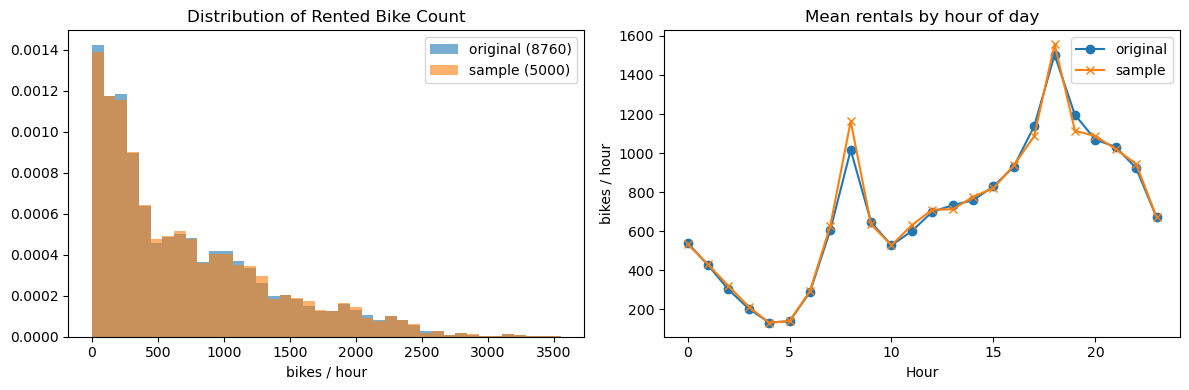

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df[TARGET], bins=40, alpha=0.6, density=True, label="original (8760)")
axes[0].hist(sample[TARGET], bins=40, alpha=0.6, density=True, label="sample (5000)")
axes[0].set_title("Distribution of Rented Bike Count")
axes[0].set_xlabel("bikes / hour")
axes[0].legend()

df.groupby("Hour")[TARGET].mean().plot(ax=axes[1], marker="o", label="original")
sample.groupby("Hour")[TARGET].mean().plot(ax=axes[1], marker="x", label="sample")
axes[1].set_title("Mean rentals by hour of day")
axes[1].set_ylabel("bikes / hour")
axes[1].legend()

plt.tight_layout()
plt.show()

In [9]:
dates = pd.to_datetime(sample["Date"], format="%d/%m/%Y")
print("Date range of the sample:", dates.min().date(), "-", dates.max().date())

Date range of the sample: 2017-12-01 - 2018-11-30


## 4. Save as UTF-8 CSV

In [10]:
sample.to_csv(OUT_PATH, index=False, encoding="utf-8")

check = pd.read_csv(OUT_PATH, encoding="utf-8")  # must load without errors
print(OUT_PATH, check.shape)
print(check.columns.tolist())

..\data\seoul_bike_5000.csv (5000, 14)
['Date', 'Rented Bike Count', 'Hour', 'Temperature(°C)', 'Humidity(%)', 'Wind speed (m/s)', 'Visibility (10m)', 'Dew point temperature(°C)', 'Solar Radiation (MJ/m2)', 'Rainfall(mm)', 'Snowfall (cm)', 'Seasons', 'Holiday', 'Functioning Day']
